# Unidad 8 - Computación III
Carrera Física Aplicada, INSPT UTN<br>
Daiana Dominikow. Noviembre 2026.

# PySerial: leer y almacenar datos de sensor Arduino.
<p style="background-color:rgba(255, 99, 71, 0.6);">Disclaimer: esto no funciona en Google Colab. Solo pueden utilizarlo localmente. Colab procesa en la nube, no en nuestra compu, por lo tanto no tiene manera de acceder a los puertos USB locales. Recomiendo utilizar VScode con la extensión de Jupyter Notebooks para este fin</p>

Al día de hoy deben estar ya familiarizados con nuestros amigos paquetes **Numpy**, **Pandas** y **MatplotLib**, la santa trinidad del análisis de datos y la física computacional en Python.<br><br>
Hoy les vengo a traer del pasado un viejo amigo: la placa de Arduino.<br><br>
Recordarán que tomar datos con un sensor Arduino y guardarlos (en general) requería  de un trabajo manual y operativo de copiar lo impreso por Serial Monitor y pegarlo en un archivo de texto. (Ojo, esto se puede automatizar con un módulo para tarjetas SD y una biblioteca hecha para tal fin, pero no disponemos de tales herramientas, y con Python podemos rabajar y luego analizar la data de manera mas sencilla).<br><br>

### Pequeña introducción, qué es el Serial?
Si tienen a mano código _C_ escrito durante la cursada de Compu 2, han de encontrar que utilizábamos un método 'Serial', inicializandolo como <em>Serial.begin(9600);</em> para imprimir por consola con el método <em>Serial.println(variable)</em> dentro del loop.<br><br>
El Serial en Arduino refiere a un puerto de comunicación, es un recurso utilizado para comunicar al Arduino y la computadora, un módulo, o incluso otro Arduino.<br> Podemos establecer comunicación con el microcontrolador a través de puertos USB, dispositivos bluetooth, etc, así como recibir y ver los datos de la comunicación. <br>

<strong>PySerial</strong> es una biblioteca que permite conectarse a todos los puertos serial disponibles, con ella vamos a poder primero buscar en qué puerto está conectado nuestro Arduino. Con este dato, y el BAUD (los bits por segundo que transmite el microcontrolador al serial, en general son 300, 600, 1200, 2400, 4800, 9600, 14400, 19200, 28800, 38400, 57600, o 115200) podremos conectarnos con python a la placa y obtener los datos del sensor que le querramos poner.

In [ ]:
#para instalar PySerial, ejecutamos
!pip install PySerial

Lo primero es entonces, importar la biblioteca

In [8]:
import serial #para leer la data del arduino uno
import serial.tools.list_ports as lp
import numpy as np
import matplotlib.pyplot as plt

Ahora, supongamos que quiero encontrar en qué puerto tengo conectada mi placa, **a la que previamente le cargué un script que toma la info de un sensor fotoresistor que va a devolver un dato numérico entre 0 y 1023.**

In [9]:
### para ver en que puerto tengo el sensor en cuestión
#esta es la versión facil, listar todos los puertos disponibles
ports = list(lp.comports())

for p in ports:
    print(p)

/dev/ttyS1 - n/a
/dev/ttyS0 - n/a
/dev/ttyACM0 - ttyACM0


Como observarán mas arriba, mi arduino esta en el puerto '/dev/ttyACM0' al momento de ejecutar este script. El gran problema de esta biblioteca está en que desde Google Colab no es util ya que no ejecuta localmente, por lo tanto no ve los puertos de la compu.
### Cómo conecto mi script jupyter a mi placa arduino?

In [13]:
#declaro dos variables, el puerto donde esta conectada la placa y el BAUD

puerto_arduino = '/dev/ttyACM0' #el puerto 
baud = 9600 #velocidad de comunicación entre la compu y el arduino

#con el merodo serial.Serial(puerto, baud) puedo conectarme a la placa.

arduino = serial.Serial(port=puerto_arduino, baudrate=baud)  
print(f'Conectado exitosamente al puerto: {puerto_arduino} BAUD rate: {baud}')

Conectado exitosamente al puerto: /dev/ttyACM0 BAUD rate: 9600


In [ ]:
#para cerrar la conexión

#arduino.close()

### Leer información del Serial
<em>no se apuren, ya vamos a repasar Arduino, supongamos tenemos un sensor del año pasado armado</em>
Veamos que podría leer continuamente la info de arduino e imprimirla.

In [14]:
def read_sensor_data():
    data = arduino.readline().decode('utf-8').strip()
    print(f'leyendo info sensor: {int(data)}')
 
while True:
    read_sensor_data()


leyendo info sensor: 905
leyendo info sensor: 905
leyendo info sensor: 904
leyendo info sensor: 905
leyendo info sensor: 660
leyendo info sensor: 662
leyendo info sensor: 663
leyendo info sensor: 668
leyendo info sensor: 904
leyendo info sensor: 908
leyendo info sensor: 908
leyendo info sensor: 909
leyendo info sensor: 910
leyendo info sensor: 907
leyendo info sensor: 717
leyendo info sensor: 715
leyendo info sensor: 593
leyendo info sensor: 377
leyendo info sensor: 318
leyendo info sensor: 307
leyendo info sensor: 302
leyendo info sensor: 477
leyendo info sensor: 336
leyendo info sensor: 320
leyendo info sensor: 904
leyendo info sensor: 904


KeyboardInterrupt: 

Pero como vimos, si lo ejecutamos así como está, el loop no vá a cortar nunca.
Tenemos que acotarlo en el tiempo, la biblioteca time la vamos a utilizar para ver en qué momento arranca el script y definirle durante cuanto tiempo queremos que mida el tiempo

In [15]:
import time
t_end = time.time() + 6  #supongamos que quiero que corra mi script durante 5 segundos.

while time.time() < t_end:
    read_sensor_data()


leyendo info sensor: 903
leyendo info sensor: 903
leyendo info sensor: 903
leyendo info sensor: 827
leyendo info sensor: 527
leyendo info sensor: 335
leyendo info sensor: 287
leyendo info sensor: 283
leyendo info sensor: 521
leyendo info sensor: 574


### Leer la información del Serial y guardarla en un array numpy.
Esto es lo importante ya que si no guardamos la información muy dificilmente podamos trabajarla luego, y es el objetivo de este módulo

In [16]:
#inicializamos el array
def save_sensor_data():
    data = arduino.readline().decode('utf-8').strip()
    print(f"Guardando data sensor a las {time.strftime('%H:%M:%S')}: {data}")
    return data 

datos = np.array([])

t_end = time.time() + 10  #supongamos que quiero que corra mi script durante 5 segundos.

while time.time() < t_end:
    data = save_sensor_data()
    datos = np.append(datos, int(data))


Guardando data sensor a las 17:01:09: 903
Guardando data sensor a las 17:01:09: 904
Guardando data sensor a las 17:01:09: 904
Guardando data sensor a las 17:01:09: 903
Guardando data sensor a las 17:01:10: 903
Guardando data sensor a las 17:01:11: 639
Guardando data sensor a las 17:01:12: 648
Guardando data sensor a las 17:01:13: 551
Guardando data sensor a las 17:01:14: 401
Guardando data sensor a las 17:01:15: 723
Guardando data sensor a las 17:01:16: 897
Guardando data sensor a las 17:01:17: 691
Guardando data sensor a las 17:01:18: 315
Guardando data sensor a las 17:01:19: 305


Ahora si! imprimo la info que guardé del sensor

In [17]:
print(datos)

[903. 904. 904. 903. 903. 639. 648. 551. 401. 723. 897. 691. 315. 305.]


Podría plotearla y realizar el análisis que quisiera con ella ;)

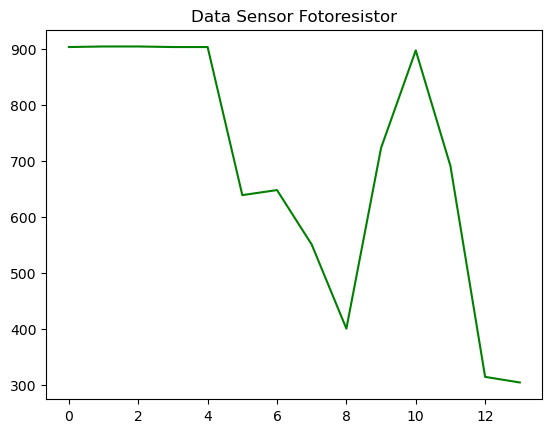

In [18]:
plt.plot(datos, color = 'green')
plt.title('Data Sensor Fotoresistor')
plt.show()